# Trade Reconciliation: Summit Capital

**Role:** Operations analyst at Summit Capital, a (fictional) firm that trades US stocks for its clients.

**The problem:** every trade is recorded twice:
1. **`internal_trades`**: what Summit's traders booked
2. **`custodian_records`**: what the custodian bank says actually happened

They should match. They don't always. My job is to find every mismatch (**break**), measure how much money is at risk, see how long it has been open, and recommend fixes.

**Reconciliation date:** Monday, 16 November 2026. US stocks settle **T+1** (one business day after the trade date).


## 0. Setup

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RECON_DATE = "2026-11-16"   # the day you're running the reconciliation
PRICE_TOLERANCE = 0.01      # price differences at or below this are rounding, not breaks
AMOUNT_TOLERANCE = 0.01     # same idea for net cash amounts

# Load both CSV files into an in-memory SQLite database
conn = sqlite3.connect(":memory:")
pd.read_csv("data/internal_trades.csv").to_sql("internal_trades", conn, index=False)
pd.read_csv("data/custodian_records.csv").to_sql("custodian_records", conn, index=False)

def q(sql):
    """Run a SQL query and return the result as a table."""
    return pd.read_sql(sql, conn)

print("SQLite version:", sqlite3.sqlite_version)

SQLite version: 3.41.2


## 1. Get to know the data

| `internal_trades` | Meaning |
|---|---|
| trade_id | Summit's reference for the trade |
| trade_date / expected_settle_date | When it was traded / when it should settle (T+1) |
| account, ticker, side, quantity, price | What was traded, for which client |
| commission | Broker fee |
| net_amount | Cash that should move (BUY = qty × price + commission, SELL = qty × price − commission) |
| counterparty | The broker on the other side of the trade |

| `custodian_records` | Meaning |
|---|---|
| custodian_ref | The custodian's own reference |
| trade_id | Summit's reference, as the custodian received it |
| actual_settle_date | When it really settled (blank if it hasn't) |
| status | SETTLED, PENDING, or FAILED |

In [2]:
q("SELECT * FROM internal_trades LIMIT 5")

,trade_id,trade_date,expected_settle_date,account,ticker,side,quantity,price,commission,net_amount,counterparty
0,SC-000001,2026-10-01,2026-10-02,ACC-1003,XOM,BUY,1500,111.6622,7.5,167500.80,Birch Markets
1,SC-000002,2026-10-01,2026-10-02,ACC-1006,JPM,SELL,200,231.6569,5.0,46326.38,Alder Securities
2,SC-000003,2026-10-01,2026-10-02,ACC-1002,AAPL,BUY,250,239.2369,5.0,59814.22,Alder Securities
3,SC-000004,2026-10-01,2026-10-02,ACC-1006,PFE,SELL,200,27.6606,5.0,5527.12,Elm Capital Markets
4,SC-000005,2026-10-01,2026-10-02,ACC-1005,XOM,BUY,100,116.0070,5.0,11605.70,Birch Markets


In [3]:
q("SELECT * FROM custodian_records LIMIT 5")

,custodian_ref,trade_id,ticker,side,quantity,price,net_amount,actual_settle_date,status
0,CUS-700001,SC-000106,AAPL,BUY,3000,221.74,665231.40,2026-10-14,SETTLED
1,CUS-700002,SC-000096,DIS,SELL,200,101.50,20294.28,2026-10-13,SETTLED
2,CUS-700003,SC-000084,PG,SELL,2500,173.04,432587.50,2026-10-12,SETTLED
3,CUS-700004,SC-000309,AMZN,SELL,2500,180.92,452285.50,2026-11-09,SETTLED
4,CUS-700005,SC-000156,BAC,SELL,500,42.95,21470.60,2026-10-20,SETTLED


In [4]:
q("""
SELECT (SELECT COUNT(*) FROM internal_trades)   AS internal_rows,
       (SELECT COUNT(*) FROM custodian_records) AS custodian_rows
""")

,internal_rows,custodian_rows
0,402,398


*The two tables are kept by different parties (Summit and its custodian), so their row counts can differ when one side is missing a trade the other has, or when a trade is booked twice as a duplicate row. Because problems on both sides can cancel out, I’ll match trade by trade instead of comparing totals.*

## 2. Why tolerance matters

A naive check compares prices exactly:

In [5]:
q("""
SELECT COUNT(*) AS trades_with_any_price_difference
FROM internal_trades i
JOIN custodian_records c ON i.trade_id = c.trade_id
WHERE i.price <> c.price
""")

,trades_with_any_price_difference
0,391


Almost every trade "differs". Summit records prices to **4 decimals**, but the custodian reports **2 decimals**. Those are rounding differences, not real breaks.

In a real Operations team, flagging hundreds of false breaks would bury the real ones. That's why we only count a price as a break when the difference is **greater than `PRICE_TOLERANCE`** ($0.01).

## 3. Find one-sided trades

Some trades exist on only one side:
- **Missing at custodian:** Summit booked it, the custodian has no record. The instruction may never have been sent.
- **Missing internally:** the custodian has it, Summit doesn't. Someone forgot to book a trade. This is serious, because Summit's books are wrong.


In [6]:
sql_missing_at_custodian = """
SELECT i.trade_id, i.ticker, i.quantity, c.trade_id AS cust_trade_id, c.status
FROM internal_trades i
LEFT JOIN custodian_records c ON i.trade_id = c.trade_id
WHERE c.trade_id IS NULL
"""
q(sql_missing_at_custodian)

,trade_id,ticker,quantity,cust_trade_id,status
0,SC-000402,BAC,1500,None,None
1,SC-000158,PFE,2000,None,None
2,SC-000313,PFE,1000,None,None
3,SC-000401,DIS,300,None,None
4,SC-000329,NVDA,300,None,None
5,SC-000382,JNJ,200,None,None
6,SC-000385,PFE,1000,None,None


In [7]:
sql_missing_internally = """
SELECT c.trade_id, c.net_amount, c.actual_settle_date 
FROM custodian_records c
LEFT JOIN internal_trades i ON i.trade_id = c.trade_id
WHERE i.trade_id IS NULL
"""
q(sql_missing_internally)

,trade_id,net_amount,actual_settle_date
0,SC-000405,87875.0,2026-10-08
1,SC-000403,73040.0,2026-11-11
2,SC-000404,28105.0,2026-10-22


## 4. Find duplicate bookings

Sometimes a trader keys the **same trade twice**. That creates two internal trade IDs, but the custodian only has one.

The duplicate will also look like "missing at custodian", so I need to catch it **first** and label it correctly.


In [8]:
sql_duplicates = """
SELECT i2.trade_id
FROM internal_trades i1
JOIN internal_trades i2
  ON i1.trade_date = i2.trade_date
 AND i1.account = i2.account
 AND i1.ticker = i2.ticker
 AND i1.side = i2.side
 AND i1.quantity = i2.quantity
 AND i1.price = i2.price
 AND i1.counterparty = i2.counterparty
 AND i1.trade_id < i2.trade_id
"""
q(sql_duplicates)

,trade_id
0,SC-000402
1,SC-000401


## 5. Classify every trade

Give every internal trade exactly **one** label. Check the most serious problems first, because a trade with the wrong side will usually have the wrong amount too, and I want the root cause.

| Order | Break type | Rule |
|---|---|---|
| 1 | Duplicate booking | trade_id is in your section 4 result |
| 2 | Missing at custodian | no custodian record |
| 3 | Wrong side | BUY vs SELL differ |
| 4 | Quantity mismatch | quantities differ |
| 5 | Price mismatch | `ABS(price difference) > PRICE_TOLERANCE` |
| 6 | Amount mismatch | `ABS(net_amount difference) > AMOUNT_TOLERANCE` |
| 7 | Failed settlement | custodian status is FAILED |
| 8 | Pending past due | status is PENDING **and** expected_settle_date is before RECON_DATE |
| 9 | Late settlement | SETTLED, but actual_settle_date is after expected_settle_date |
| - | Matched | everything else |

> A trade that is PENDING but **not due yet** (expected to settle after RECON_DATE) is normal. It's not a break.

In [9]:
sql_classify = f"""
WITH dup AS (
   {sql_duplicates}
)
SELECT
    i.trade_id,
    i.counterparty,
    i.expected_settle_date,
    c.actual_settle_date,
    i.net_amount AS internal_amount,
    c.net_amount AS custodian_amount,
    CASE
        WHEN i.trade_id IN (SELECT trade_id FROM dup) THEN 'Duplicate booking'
        WHEN c.trade_id IS NULL                        THEN 'Missing at custodian'
        WHEN i.side <> c.side                          THEN 'Wrong side'
        WHEN i.quantity <> c.quantity                  THEN 'Quantity mismatch'
        WHEN ABS(i.price - c.price) > {PRICE_TOLERANCE} THEN 'Price mismatch'
        WHEN ABS(i.net_amount - c.net_amount) > {AMOUNT_TOLERANCE} THEN 'Amount mismatch'
        WHEN c.status = 'FAILED' THEN 'Failed settlement'
        WHEN c.status = 'PENDING'
            AND i.expected_settle_date < '{RECON_DATE}' THEN 'Pending past due'
        WHEN c.status = 'SETTLED'
            AND c.actual_settle_date > i.expected_settle_date Then 'Late settlement'
        ELSE 'Matched'
    END AS break_type
FROM internal_trades i
LEFT JOIN custodian_records c ON i.trade_id = c.trade_id
"""
classified = q(sql_classify)
classified["break_type"].value_counts()

break_type
Matched                 368
Quantity mismatch         5
Price mismatch            5
Missing at custodian      5
Amount mismatch           4
Late settlement           4
Failed settlement         4
Pending past due          3
Duplicate booking         2
Wrong side                2
Name: count, dtype: int64

## 6. Build the break report

One row per break, with:
- **exposure_usd:** money at risk. For quantity, price and amount mismatches, it's the *difference* between the two net amounts. For everything else, it's the full net amount.
- **age_days:** how long the break has been open. 
- **priority:** what to escalate first. 

In [10]:
# Internal-side breaks from section 5
internal_breaks = classified[classified["break_type"] != "Matched"].copy()

# Custodian-only breaks from section 3
cust_only = q(sql_missing_internally)
if "trade_id" in cust_only.columns:
    cust_only = pd.DataFrame({
        "trade_id": cust_only["trade_id"],
        "counterparty": "Unknown (not booked)",
        "expected_settle_date": cust_only["actual_settle_date"],
        "actual_settle_date": cust_only["actual_settle_date"],
        "internal_amount": np.nan,
        "custodian_amount": cust_only["net_amount"],
        "break_type": "Missing internally",
    })
else:
    cust_only = pd.DataFrame(columns=internal_breaks.columns)

breaks = pd.concat([internal_breaks, cust_only], ignore_index=True)

# Exposure
is_mismatch = breaks["break_type"].isin(["Quantity mismatch", "Price mismatch", "Amount mismatch"])
breaks["exposure_usd"] = np.where(
    is_mismatch,
    (breaks["internal_amount"] - breaks["custodian_amount"]).abs(),
    breaks["internal_amount"].fillna(breaks["custodian_amount"]).abs(),
).round(2)

print(len(breaks), "breaks so far")

37 breaks so far


In [11]:
expected = pd.to_datetime(breaks["expected_settle_date"])
actual = pd.to_datetime(breaks["actual_settle_date"])
recon = pd.Timestamp(RECON_DATE)

breaks["age_days"] = np.where(
    breaks["break_type"] == "Late settlement", 
    (actual - expected).dt.days,    #late trades: how many days late they settled
    (recon - expected).dt.days,     # everything else: days open as of today
)

In [12]:
# Priority rules
# 'Resolved' if the break is a Late settlement (it already settled)
# 'High'     if Wrong side, Missing internally, exposure_usd >= 100,000, or age_days > 5
# 'Medium'   if exposure_usd >= 25,000 or age_days >= 2
# 'Low'      otherwise

def priority(row):
    if row["break_type"] == "Late settlement":
        return "Resolved"
    if row["break_type"] in ("Wrong side", "Missing internally") or row["exposure_usd"] >= 100_000 or row["age_days"] > 5:
        return "High"
    if row["exposure_usd"] >= 25_000 or row["age_days"] >= 2:
        return "Medium"
    return "Low"  

breaks["priority"] = breaks.apply(priority, axis=1)

break_report = breaks[["trade_id", "break_type", "counterparty", "exposure_usd", "age_days", "priority"]] \
    .sort_values(["priority", "exposure_usd"], ascending=[True, False]).reset_index(drop=True)
break_report

,trade_id,break_type,counterparty,exposure_usd,age_days,priority
0,SC-000010,Quantity mismatch,Dune Brokerage,1185068.88,45.0,High
1,SC-000131,Failed settlement,Dune Brokerage,504854.50,31.0,High
2,SC-000171,Wrong side,Dune Brokerage,442426.00,26.0,High
3,SC-000327,Pending past due,Elm Capital Markets,430806.00,6.0,High
4,SC-000132,Quantity mismatch,Alder Securities,425234.34,31.0,High
5,SC-000374,Pending past due,Dune Brokerage,159475.80,3.0,High
6,SC-000260,Failed settlement,Alder Securities,90334.33,14.0,High
7,SC-000405,Missing internally,Unknown (not booked),87875.00,39.0,High
8,SC-000403,Missing internally,Unknown (not booked),73040.00,5.0,High
9,SC-000402,Duplicate booking,Cedar Trading,62618.40,42.0,High


## 7. Results

In [13]:
total_trades = len(classified)
match_rate = (classified["break_type"] == "Matched").mean()
open_breaks = break_report[break_report["priority"] != "Resolved"]

print(f"Trades reconciled:      {total_trades}")
print(f"Auto-match rate:        {match_rate:.1%}")
print(f"Breaks found:           {len(break_report)}  ({len(open_breaks)} still open)")
print(f"Open exposure:          ${open_breaks['exposure_usd'].sum():,.0f}")

Trades reconciled:      402
Auto-match rate:        91.5%
Breaks found:           37  (33 still open)
Open exposure:          $3,905,635


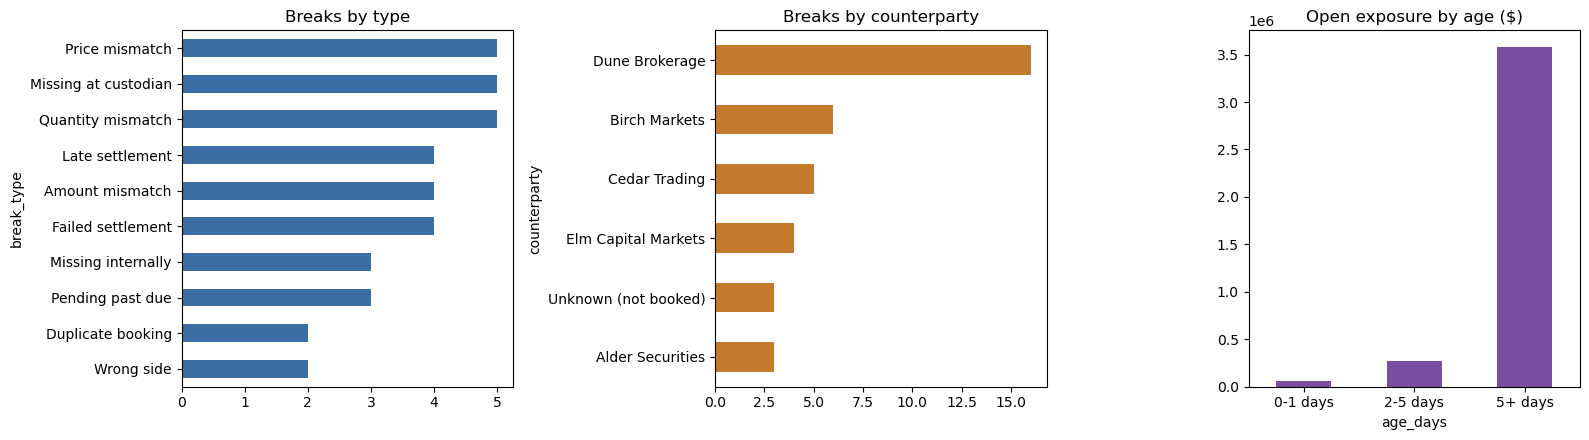

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

break_report["break_type"].value_counts().sort_values().plot.barh(ax=axes[0], color="#3b6ea5")
axes[0].set_title("Breaks by type")

break_report["counterparty"].value_counts().sort_values().plot.barh(ax=axes[1], color="#c47a2c")
axes[1].set_title("Breaks by counterparty")

buckets = pd.cut(open_breaks["age_days"], [-1, 1, 5, np.inf], labels=["0-1 days", "2-5 days", "5+ days"])
open_breaks.groupby(buckets, observed=False)["exposure_usd"].sum().plot.bar(ax=axes[2], color="#7a4fa0", rot=0)
axes[2].set_title("Open exposure by age ($)")

plt.tight_layout()
plt.show()

In [15]:
# Top 10 breaks to escalate
open_breaks[open_breaks["priority"] == "High"].sort_values("exposure_usd", ascending=False).head(10)

,trade_id,break_type,counterparty,exposure_usd,age_days,priority
0,SC-000010,Quantity mismatch,Dune Brokerage,1185068.88,45.0,High
1,SC-000131,Failed settlement,Dune Brokerage,504854.50,31.0,High
2,SC-000171,Wrong side,Dune Brokerage,442426.00,26.0,High
3,SC-000327,Pending past due,Elm Capital Markets,430806.00,6.0,High
4,SC-000132,Quantity mismatch,Alder Securities,425234.34,31.0,High
5,SC-000374,Pending past due,Dune Brokerage,159475.80,3.0,High
6,SC-000260,Failed settlement,Alder Securities,90334.33,14.0,High
7,SC-000405,Missing internally,Unknown (not booked),87875.00,39.0,High
8,SC-000403,Missing internally,Unknown (not booked),73040.00,5.0,High
9,SC-000402,Duplicate booking,Cedar Trading,62618.40,42.0,High


## 8. Export for Power BI

In [16]:
import os
os.makedirs("outputs", exist_ok=True)
break_report.to_csv("outputs/break_report.csv", index=False)
classified.to_csv("outputs/all_trades_classified.csv", index=False)
print("Saved outputs/break_report.csv and outputs/all_trades_classified.csv")

Saved outputs/break_report.csv and outputs/all_trades_classified.csv


In [17]:
# 1. Which counterparty causes the most breaks?
by_cp = break_report["counterparty"].value_counts()
print("Breaks by counterparty:")
print(pd.DataFrame({"breaks": by_cp, "share": (by_cp / len(break_report) * 100).round(0).astype(int).astype(str) + "%"}))

# 2. What kinds of breaks does the top counterparty cause?
top_cp = by_cp.index[0]
print(f"\nBreak types for {top_cp}:")
print(break_report[break_report["counterparty"] == top_cp]["break_type"].value_counts())

# 3. Biggest open breaks
print("\nLargest open exposures:")
print(open_breaks.sort_values("exposure_usd", ascending=False).head(3)[["trade_id", "break_type", "counterparty", "exposure_usd", "age_days"]])

# 4. How much exposure sits in each priority?
print("\nExposure by priority:")
print(break_report.groupby("priority")["exposure_usd"].agg(["count", "sum"]))

Breaks by counterparty:
                      breaks share
counterparty                      
Dune Brokerage            16   43%
Birch Markets              6   16%
Cedar Trading              5   14%
Elm Capital Markets        4   11%
Alder Securities           3    8%
Unknown (not booked)       3    8%

Break types for Dune Brokerage:
break_type
Price mismatch          4
Quantity mismatch       3
Missing at custodian    3
Failed settlement       1
Wrong side              1
Pending past due        1
Duplicate booking       1
Amount mismatch         1
Late settlement         1
Name: count, dtype: int64

Largest open exposures:
    trade_id         break_type    counterparty  exposure_usd  age_days
0  SC-000010  Quantity mismatch  Dune Brokerage    1185068.88      45.0
1  SC-000131  Failed settlement  Dune Brokerage     504854.50      31.0
2  SC-000171         Wrong side  Dune Brokerage     442426.00      26.0

Exposure by priority:
          count        sum
priority                  
Hi

## 9. Root cause and recommendations

1. Root cause: Dune Brokerage caused 43% of breaks (16 of 37), more than twice its 20% fair share. Its top issues were price mismatches (4), quantity mismatches (3) and trades missing at the custodian (3). These are data and booking errors, not settlement failures, which points to weak trade confirmation between Summit and Dune.
2. Biggest risk: SC-000010 is a quantity mismatch: 3,000 shares booked vs 300 settled, likely a manual entry error. It carries $1.19M of exposure and has been open 45 days. I would escalate it to my manager and the trading desk today, and confirm the correct quantity with Dune.
3. Control gap: Summit’s own books had errors too: 2 trades were booked twice and 3 settled trades were never booked. Not every break is the counterparty’s fault.
4. Recommendation: Introduce same-day trade confirmation with Dune and run this reconciliation daily instead of letting breaks age. Same-day confirmation would have caught about 10 of Dune’s 16 breaks before settlement, and a daily check would have flagged SC-000010 on day one, not day 45.